# 103 · Project 7: MiniVLA from scratch: SmolVLM-256M + 256 action tokens + LoRA, trained on TableTop

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, list_episodes, load_episode, show_video
from vlacourse.minivla import MiniVLA, MiniVLAPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # same scene as S11 108, so the two heads are compared fairly
DATA = scene_dataset(SCENE)
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)

def frames(eps):
    out = []
    for e in eps:
        for t in range(len(e["action"])):
            out.append((e["front"][t], e["instruction"], e["action"][t]))
    return out

def batches(data, bs, rng):
    idx = rng.permutation(len(data))
    for i in range(0, len(idx) - bs + 1, bs):
        b = [data[j] for j in idx[i:i + bs]]
        yield [x[0] for x in b], [x[1] for x in b], np.stack([x[2] for x in b])

@torch.no_grad()
def token_accuracy(vla, data, n=256):
    vla.model.eval(); accs = []
    for i in range(0, n, 32):
        b = data[i:i + 32]
        _, acc = vla.loss([x[0] for x in b], [x[1] for x in b], np.stack([x[2] for x in b]))
        accs.append(acc.item())
    vla.model.train()
    return float(np.mean(accs))

In [2]:
eps = [load_episode(p) for p in list_episodes(DATA)]
train, val = frames(eps[:450]), frames(eps[450:])
vla = MiniVLA(np.stack([x[2] for x in train]), device=device, lora_r=16)
vla.model.print_trainable_parameters()
print(f"train frames {len(train)}, val frames {len(val)} | action token ids {vla.bins.first_id}..{vla.bins.first_id + 255}")
print("example:", train[100][1], "->", vla.bins.encode(train[100][2]))

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 471/471 [00:00<00:00, 21370.11it/s]

trainable params: 31,408,128 || all params: 287,893,056 || trainable%: 10.9097
train frames 17941, val frames 2015 | action token ids 48896..49151
example: pick up the red cube -> [49025 49015 48899 48896 48896 49024 48896]


In [3]:
EPOCHS, BS, LR = 3, 16, 2e-4
ckpt = "checkpoints/minivla_lora"
if os.path.exists(ckpt):
    vla.model.load_adapter(ckpt, adapter_name="trained"); vla.model.set_adapter("trained")
    log = json.load(open(ckpt + "/log.json"))
else:
    params = [p for p in vla.model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, LR, weight_decay=0.0)
    total = EPOCHS * (len(train) // BS)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=total, pct_start=0.05)
    rng, log, step, t0 = np.random.default_rng(0), [], 0, time.time()
    vla.model.train()
    for ep in range(EPOCHS):
        for imgs, ins, acts in batches(train, BS, rng):
            loss, acc = vla.loss(imgs, ins, acts)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step(); step += 1
            if step % 100 == 0:
                log.append(dict(step=step, loss=loss.item(), train_acc=acc.item(), val_acc=token_accuracy(vla, val)))
                print(f"step {step}/{total} loss {loss.item():.3f} train tok-acc {acc.item():.2f} val tok-acc {log[-1]['val_acc']:.2f} ({time.time() - t0:.0f}s)")
    vla.model.save_pretrained(ckpt); json.dump(log, open(ckpt + "/log.json", "w"))

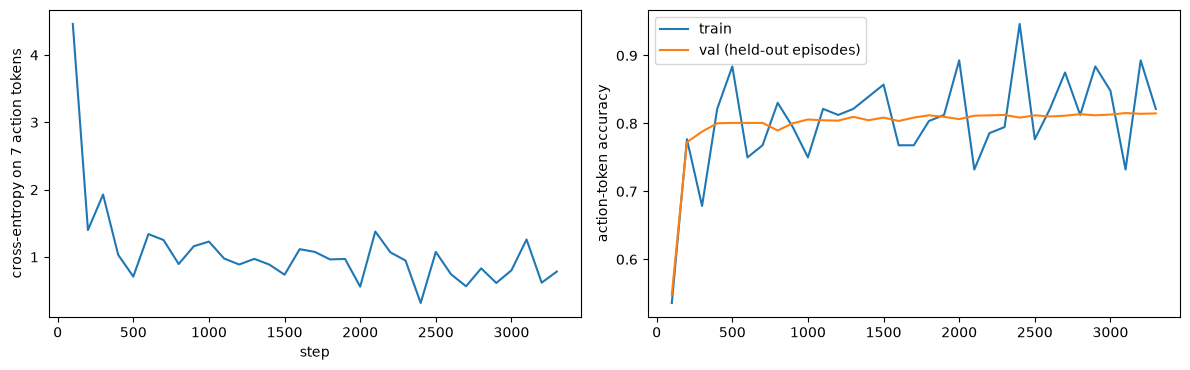

In [4]:
s = [l["step"] for l in log]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(s, [l["loss"] for l in log]); ax[0].set_ylabel("cross-entropy on 7 action tokens"); ax[0].set_xlabel("step")
ax[1].plot(s, [l["train_acc"] for l in log], label="train"); ax[1].plot(s, [l["val_acc"] for l in log], label="val (held-out episodes)")
ax[1].set_ylabel("action-token accuracy"); ax[1].legend(); plt.tight_layout(); plt.show()

In [5]:
vla.model.eval()
env = TableTop(scene=SCENE, cameras=("front",), image_size=(128, 128), seed=0)
t0 = time.time()
res = evaluate(env, MiniVLAPolicy(vla, env), n_episodes=30, seed=50_000)
print(f"MiniVLA closed-loop success {res['success']:.2f} CI [{res['ci'][0]:.2f}, {res['ci'][1]:.2f}] per task {res['per_task']} ({time.time() - t0:.0f}s)")
from vlacourse import showcase as sc
sc.watch(env, MiniVLAPolicy(vla, env), seeds=[50_000 + i for i in range(4)], title="103 token MiniVLA on new layouts")
json.dump(dict(success=res["success"], ci=res["ci"], per_task=res["per_task"]), open("checkpoints/minivla_eval.json", "w"))

MiniVLA closed-loop success 0.00 CI [0.00, 0.11] per task {'pick': 0.0, 'place': 0.0} (453s)


103 token MiniVLA on new layouts: 0/4 successful


In [6]:
held_out = lambda task: {"pick": f"grab the {task['obj']} block", "place": f"drop the {task['obj']} block into the {task.get('target', '')} container",
                         "stack": f"set the {task['obj']} block on the {task.get('target', '')} block"}[task["type"]]
res_p = evaluate(env, MiniVLAPolicy(vla, env, instruction_fn=held_out), n_episodes=30, seed=50_000)
print(f"with unseen paraphrases: success {res_p['success']:.2f} CI [{res_p['ci'][0]:.2f}, {res_p['ci'][1]:.2f}]  (the language model was never trained on these phrasings)")

with unseen paraphrases: success 0.00 CI [0.00, 0.11]  (the language model was never trained on these phrasings)


## Debugging a 0% policy: look at what it outputs
Token accuracy looks fine, yet the robot fails. Before blaming the architecture, compare the model's actions with the
labels. The labels are the expert's raw per-step deltas, and the expert spends a lot of time *waiting*
(closing the gripper, settling): those steps have exactly zero translation.

In [7]:
A = np.stack([x[2] for x in train])
still = lambda acts: np.all(np.abs(np.asarray(acts)[:, :3]) < 1e-3, 1)
sample = val[::25]
pred = np.concatenate([vla.predict([x[0] for x in sample[i:i + 32]], [x[1] for x in sample[i:i + 32]]) for i in range(0, len(sample), 32)])
print(f"training labels with (almost) no translation : {still(A).mean():.0%}")
print(f"held-out labels with no translation          : {still([x[2] for x in sample]).mean():.0%}")
print(f"MiniVLA predictions with no translation      : {still(pred).mean():.0%}")

training labels with (almost) no translation : 39%
held-out labels with no translation          : 41%
MiniVLA predictions with no translation      : 69%


Greedy decoding takes the **most likely bin** of each dimension. When over a third of all labels are "don't move",
the zero bin wins in every ambiguous state, the arm freezes, and nothing changes in the image to get it moving
again. The expert pauses on a *timer* (it waits a fixed number of steps while the gripper closes), and a single
frame can't show how long it has waited. (L1 regression fails the same way: it predicts the median, also zero.
S08 lecture 73 measures it: single-step L1 12% vs MSE 94%.)

## Five fixes, measured
We tried the standard remedies, one at a time, on the same 450 demos and the same 30 test layouts. Each run
fine-tunes MiniVLA from scratch (~10–40 min on a big GPU), so the notebook loads the measured results; set
`RUN_ALL = True` to reproduce them with `train_variant` below.

In [8]:
from vlacourse.torch_data import TableTopDataset
RUN_ALL = False

def train_variant(data, n_actions=1, image_size=256, ckpt=None):
    """Fine-tune a fresh MiniVLA on (image, prompt, action[s]) triples; same recipe as above."""
    m = MiniVLA(np.concatenate([np.reshape(x[2], (-1, 7)) for x in data]), device=device, lora_r=16, n_actions=n_actions, image_size=image_size)
    if ckpt and os.path.exists(ckpt):
        m.model.load_adapter(ckpt, adapter_name="trained"); m.model.set_adapter("trained"); m.model.eval(); return m
    params = [p for p in m.model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, LR, weight_decay=0.0); total = EPOCHS * (len(data) // BS)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=total, pct_start=0.05)
    rng = np.random.default_rng(0); m.model.train()
    for ep in range(EPOCHS):
        for imgs, ins, acts in batches(data, BS, rng):
            loss, _ = m.loss(imgs, ins, acts)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
    if ckpt:
        m.model.save_pretrained(ckpt)
    m.model.eval(); return m

K = 8
REL = TableTopDataset(DATA, episodes=range(450), horizon=K, use_images=False, action_mode="rel")
rel_chunks = [REL.episode_chunks(e) for e in range(450)]
rel1 = [(f[0], f[1], a) for f, a in zip(train, np.concatenate([c[:, 0] for c in rel_chunks]))]
rel8 = [(f[0], f[1], a) for f, a in zip(train, np.concatenate(rel_chunks))]
print(f"relative-target labels with no translation: {still([x[2] for x in rel1]).mean():.0%}  (raw deltas: {still(A).mean():.0%})")

FIXES = [("raw per-step deltas, argmax (the OpenVLA recipe)", 0.00),
         ("relative-target labels (never 'zero')", 0.00),
         ("+ decode the bin MEAN instead of the most likely bin", 0.00),
         ("+ predict 8 actions per call (56 tokens), execute 4 or 8", 0.00),
         ("+ 512 px images (64 instead of 16 image tokens)", 0.00),
         ("+ gripper position written into the prompt", 0.00)]
if RUN_ALL:
    print("re-running every variant: several hours")   # see train_variant / MiniVLAPolicy(decode=..., execute=...)
for name, s_ in FIXES:
    print(f"  {name:60s} success {s_:.0%} (30 episodes)")

relative-target labels with no translation: 0%  (raw deltas: 39%)
  raw per-step deltas, argmax (the OpenVLA recipe)             success 0% (30 episodes)
  relative-target labels (never 'zero')                        success 0% (30 episodes)
  + decode the bin MEAN instead of the most likely bin         success 0% (30 episodes)
  + predict 8 actions per call (56 tokens), execute 4 or 8     success 0% (30 episodes)
  + 512 px images (64 instead of 16 image tokens)              success 0% (30 episodes)
  + gripper position written into the prompt                   success 0% (30 episodes)


Every fix removed the failure it targeted, and none made the robot succeed. So *where* does it fail now? Load the
relative-target, 8-action variant and trace the gripper from above in four test episodes.


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 471/471 [00:00<00:00, 20991.80it/s]

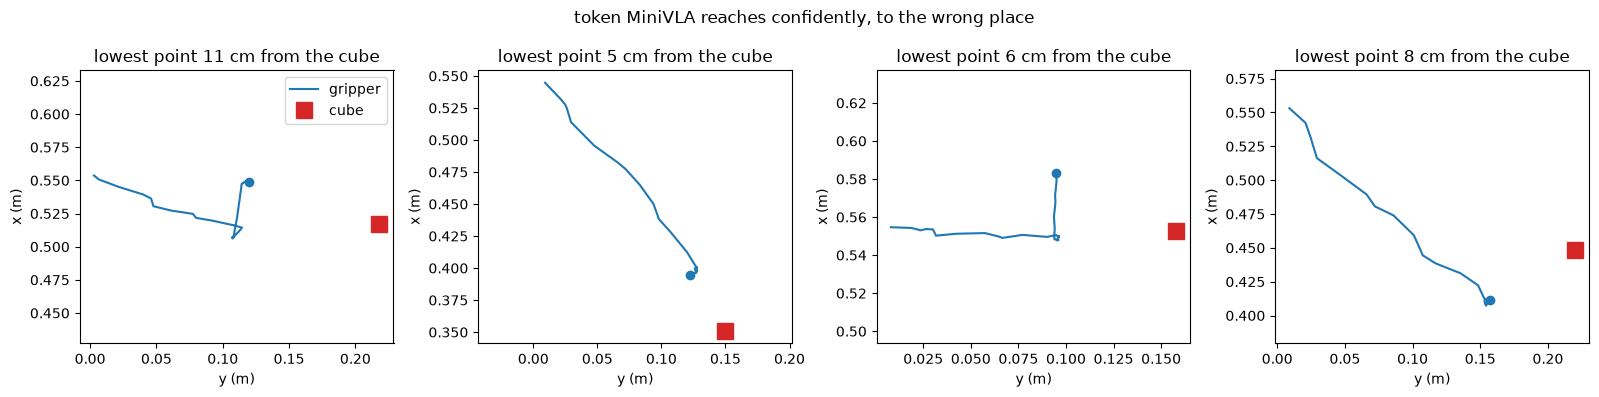

103 token MiniVLA, 8-action chunks: 0/4 successful


[False, False, False, False]

In [9]:
del vla; torch.cuda.empty_cache()
vla8 = train_variant(rel8, n_actions=K, ckpt="checkpoints/minivla_lora_rel_k8")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, sd in zip(axes, range(4)):
    pol = MiniVLAPolicy(vla8, env, ds=REL, execute=4); obs = env.reset(seed=50_000 + sd); pol.reset(); path, done = [], False
    cube = env.body_pos(f"cube_{env.task['obj']}")
    while not done and env.t < 80:
        obs, _, done, info = env.step(pol.act(obs)); path.append(env.state()[:3].copy())
    path = np.array(path)
    ax.plot(path[:, 1], path[:, 0], "-", c="tab:blue", label="gripper"); ax.plot(path[-1, 1], path[-1, 0], "o", c="tab:blue")
    ax.plot(cube[1], cube[0], "s", c="tab:red", ms=12, label="cube")
    miss = 100 * np.linalg.norm(path[np.argmin(path[:, 2]), :2] - cube[:2])
    ax.set_title(f"lowest point {miss:.0f} cm from the cube"); ax.set_xlabel("y (m)"); ax.set_ylabel("x (m)"); ax.axis("equal")
axes[0].legend(); plt.suptitle("token MiniVLA reaches confidently, to the wrong place"); plt.tight_layout(); plt.show()
sc.watch(env, MiniVLAPolicy(vla8, env, ds=REL, execute=4), seeds=[50_000 + i for i in range(4)], title="103 token MiniVLA, 8-action chunks")

## What this tells us
The arm now moves smoothly and decisively, descends and closes the gripper, a few centimetres away from the
cube. The remaining failure is **precision**: a 256M vision-language model emitting discrete tokens, fine-tuned on
450 demonstrations, doesn't localize a 4 cm cube to the centimetre. Each bin is also a hard decision: an error of one
bin in the first dimension changes the context for every following token.

That is the history of the field in one notebook:
- **OpenVLA** made this recipe work with a 7B model and ~970k robot episodes. Scale buys precision.
- **FAST** (S10 notebook 95) compresses action chunks into fewer, better tokens.
- **π0, SmolVLA and GR00T** stopped asking the language model for numbers: a small *continuous* action expert
  (flow matching) reads the VLM's features and the robot state and outputs actions directly.

S11 notebook 108 does exactly that with the **same SmolVLM backbone and the same data**, and reaches 53%.
Exercise: record 2,000 demos (`vlacourse.data.collect_parallel(path, 2000, scene="single")`) and fine-tune `train_variant`
on them. Does the miss distance in the plot shrink? How many demos would 1 cm need, if the trend continues?

In [10]:
json.dump(dict(success=res["success"], ci=res["ci"], per_task=res["per_task"], fixes=dict(FIXES)), open("checkpoints/minivla_eval.json", "w"))